# 07 · ESRI: can anything raise the score?

Notebook 06 set the score, the Figure of Merit over all change, and the reference: the deployed method with corrected inputs scores 19.1% on 2024→2025, about 2.2 times random placement. The improvement approach's history models score higher (28.6%) but fail the flip-back check: their gain is pixels going back to an earlier class. This notebook tests two ideas from the literature.

**Same design as notebook 06:** ESRI on the deployed 250 m grid, Guinea only, the
observed quantity of each transition, the deployed allocator and scorer. Settings are
chosen on **2023→2024** and tested once on **2024→2025**.

**Rule:** a configuration improves on the deployed method when, chosen on 2023→2024 only, its FoM on 2024→2025 is higher by more than the spread across random seeds, it beats random placement, and it passes the flip-back check of notebook 06 (its new-change FoM is not lower than the deployed method's). Choosing on one period and testing on another, and comparing against a random model, follow Pontius et al. (2004). Measuring the spread across seeds before claiming a gain follows Bouthillier et al. (2021).

| | Hybrid (section 2) | Seasonal satellite features (sections 3–5) |
|---|---|---|
| Idea | Model change that returns to an earlier class separately from new change | Give the models spectral evidence of whether a pixel's vegetation actually changed |
| Literature | Change that returns to an earlier category ("alternation") is a distinct component of change over time and should be reported separately (Pontius et al. 2017). Land-change models are routinely built as separate sub-models per transition (Land Change Modeler; Mas et al. 2014). The split between the two parts is estimated from the previous interval, the Markov-chain step that CA–Markov models and DINAMICA use for transition amounts (Soares-Filho et al. 2002; Mas et al. 2014). | Genuine land-cover change appears as a persistent break in a pixel's seasonal vegetation signal (BFAST, Verbesselt et al. 2010; CCDC, Zhu & Woodcock 2014). A label flip with no spectral change is more likely a classification error. Seasonal (phenology) metrics separate vegetation types that annual means do not (TIMESAT, Jönsson & Eklundh 2004). |
| Additional Data | No new data | MODIS download, then the same training as notebook 06 |


In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H
import esri_methods as E
import esri_seasonal as ES
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
RERUN = False
PH = ("validation", "test")
LABEL = {"validation": "2023→2024 (choose)", "test": "2024→2025 (test)"}
prof = E.grid(); g = H.guinea_mask(prof)

def get(tag, phase, runner):
    r = None if RERUN else E.load_result(tag, phase)
    return r if r else runner()

def predicted(tag, phase, mode="Expander-only", sub="allocation"):
    return H.read_tif(E.RUNS / tag / phase / sub / mode.replace(" ", "_") / "predicted_land_cover.tif")[0]

def two(tag, phase, mode="Expander-only", sub="allocation"):
    _, t_start, t_fore = E.phase_years(phase)
    return E.change_kind_scores(t_start, E.esri_cached(t_fore), predicted(tag, phase, mode, sub), g)

BASE = {"Deployed method": ("R0c_guinea_dated", "Expander-only", "allocation"),
        "Deployed method + history features": ("R2_history", "Expander-only", "allocation"),
        "History models, averaged": ("R4_average", "w=0.5", "allocation_w0.5")}

def row(name, by_phase):
    v, t = by_phase["validation"], by_phase["test"]
    return {"Configuration": name, "FoM % 2023→2024": v["FoM"], "FoM % 2024→2025": t["FoM"],
            "Check: new-change FoM % 2023→2024": v["new"]["FoM"], "Check: new-change FoM % 2024→2025": t["new"]["FoM"]}

## 1 · Continue from Notebook 06

All rows here use seed 42, so each comparison changes only the method.

In [2]:
base_scores = {name: {ph: two(tag, ph, mode, sub) for ph in PH} for name, (tag, mode, sub) in BASE.items()}
seeds = {ph: [two(t, ph) for t in ("R0c_guinea_dated", "R0c_guinea_dated_seed1", "R0c_guinea_dated_seed2")] for ph in PH}
spread = lambda xs: (max(xs) - min(xs)) / 2
noise = {ph: spread([x["FoM"] for x in v]) for ph, v in seeds.items()}
noise_new = {ph: spread([x["new"]["FoM"] for x in v]) for ph, v in seeds.items()}
print(f"Deployed method, spread across 3 seeds: ±{noise['validation']:.2f} points (2023→2024), "
      f"±{noise['test']:.2f} (2024→2025)")
H.show(pd.DataFrame([row(n, s) for n, s in base_scores.items()]))

Deployed method, spread across 3 seeds: ±0.05 points (2023→2024), ±0.02 (2024→2025)


Configuration,FoM % 2023→2024,FoM % 2024→2025,Check: new-change FoM % 2023→2024,Check: new-change FoM % 2024→2025
Deployed method,15.53,19.05,8.88,7.44
Deployed method + history features,25.08,28.03,5.84,3.76
"History models, averaged",25.92,28.60,5.45,3.44


## 2 · Hybrid: returns and new change modelled separately

For each transition (say Rangeland→Trees), the observed demand is split into a
**return** part and a **new** part. The split is the share of returns seen in the
previous interval (2022→2023 when choosing, 2023→2024 when testing), estimated from past
maps only, as CA–Markov models and DINAMICA estimate transition amounts. Returns are
allocated with the averaged history models' suitability, on pixels that held the
destination class in an earlier map. New change is allocated with the deployed method's
suitability, on all other pixels. Both go into one surface per transition, so the deployed
allocator runs unchanged (`E.run_hybrid`).

In [3]:
atlas = lambda tag, ph, sub, prefix: E.atlas_from(E.RUNS / tag / ph / sub, prefix)
R4_ATLAS = lambda ph: atlas("R4_average", ph, "surfaces_w0.5", "avg")
R0C_ATLAS = lambda ph: atlas("R0c_guinea_dated", ph, "surfaces", "expander")
hybrid = {ph: get("hybrid_markov", ph, lambda ph=ph: E.run_hybrid(ph, R4_ATLAS(ph), R0C_ATLAS(ph), tag="hybrid_markov"))
          for ph in PH}
split = pd.DataFrame([dict(Transition=f"{H.ESRI_CLASSES[s['transition'][0]]} → {H.ESRI_CLASSES[s['transition'][1]]}",
                           **{"Demand 2024→2025 (px)": s["demand"], "Return share used (from 2023→2024)": s["return_share_used"],
                              "Return share that happened (diagnostic only)": s["return_share_observed_diagnostic"]})
                      for s in hybrid["test"]["split"]]).sort_values("Demand 2024→2025 (px)", ascending=False)
H.show(split, 2)
hyb_scores = {"Hybrid (split from the previous interval)": {ph: two("hybrid_markov", ph, "Hybrid") for ph in PH}}
H.show(pd.DataFrame([row(n, s) for n, s in {**base_scores, **hyb_scores}.items()]))

Configuration,FoM % 2023→2024,FoM % 2024→2025,Check: new-change FoM % 2023→2024,Check: new-change FoM % 2024→2025
Deployed method,15.53,19.05,8.88,7.44
Deployed method + history features,25.08,28.03,5.84,3.76
"History models, averaged",25.92,28.60,5.45,3.44
Hybrid (split from the previous interval),22.01,26.05,8.68,5.44


**Not chosen: it fails the flip-back check.** The hybrid scores 22.0% on 2023→2024 and 26.1%
on 2024→2025, well above the deployed method (15.5% and 19.1%), because its return part uses
the history models. On genuinely new change it scores 8.68% and 5.44%, against 8.88% and 7.44%. The return shares taken from the previous interval
are close to what then happened (table above), so the split itself is not the problem.

The loss on new change comes from its volume. Both forecasts place new change with about
the same precision: roughly one in ten predicted new changes is correct. The split from the
previous interval gives new change about half the pixels (91,569 predicted against the
deployed method's 187,566), so the hybrid finds about half as many: 9,536 against 19,423.

## 3 · Seasonal satellite data

MODIS MOD13Q1 (Terra, 16-day NDVI and EVI) is natively 250 m, the grid the platform
runs on. For each year 2018–2024, twelve composites (one per month, all inside that
year), with the improvement approach's quality rule (`esri_seasonal.py`, based on
`local_landuse/modis_phenology.py`).

Twelve features per pixel and year, each from that year and the four before only:

| Group | Features | Literature |
|---|---|---|
| Phenology of the year | NDVI annual mean, amplitude (p90−p10), dry-season (Dec–Apr) and wet-season (Jun–Oct) mean, EVI mean | Seasonal metrics separate vegetation types (Jönsson & Eklundh 2004) |
| Spectral change evidence | Change in mean, amplitude and dry-season NDVI against the three previous years; departure of this year's and last year's 12-month profile from the previous three years' profile | Real change = persistent break in the seasonal signal (Verbesselt et al. 2010; Zhu & Woodcock 2014) |
| Trend | Slope of annual mean NDVI over five years | Gradual change shows as a trend, separate from seasonal variation (Verbesselt et al. 2010) |
| Data quality | Number of valid composites in the year | Lets the model discount cloudy pixels |

In [4]:
for y in range(2018, 2025):
    ES.fetch_year(y)            # no-op when cached
coverage = pd.DataFrame([json.loads((ES.ROOT / str(y) / "manifest.json").read_text()) for y in range(2018, 2025)])
coverage = coverage[["year", "composites", "coverage_any", "coverage_six_periods"]].assign(
    coverage_any=lambda d: 100 * d.coverage_any, coverage_six_periods=lambda d: 100 * d.coverage_six_periods)
coverage.columns = ["Year", "Tile composites", "% of pixels with any valid NDVI", "% with ≥ 6 valid months"]
H.show(coverage, 1)

Year,Tile composites,% of pixels with any valid NDVI,% with ≥ 6 valid months
2018,48,99.9,98.0
2019,48,99.9,96.0
2020,48,99.9,94.8
2021,48,99.9,97.2
2022,48,99.9,93.7
2023,48,99.9,98.5
2024,48,99.9,97.4


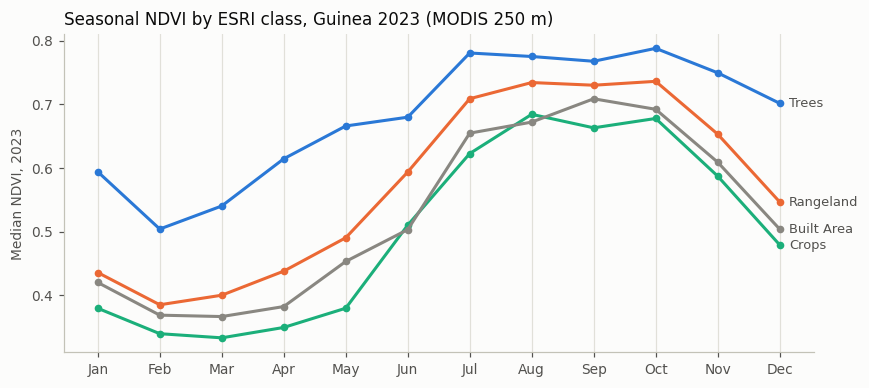

In [5]:
ndvi, _ = ES.cube(2023)
lc = E.esri_cached(2023)
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(8, 3.6))
for colour, cls in zip(H.SERIES + [H.MUTED], (2, 11, 5, 7)):
    m = g & (lc == cls)
    prof_ = np.nanmedian(ndvi[:, m], axis=1)
    ax.plot(months, prof_, color=colour, linewidth=2, marker="o", markersize=4)
    ax.annotate(H.ESRI_CLASSES[cls], (11, prof_[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=H.INK_2, fontsize=8.5)
H.style_axes(ax)
ax.set_ylabel("Median NDVI, 2023", color=H.INK_2)
ax.set_title("Seasonal NDVI by ESRI class, Guinea 2023 (MODIS 250 m)", loc="left", color=H.INK, fontsize=11)
plt.tight_layout(); plt.show()

The classes show the expected seasonal signatures. Trees stay greenest all year.
Rangeland has the largest seasonal swing. Crops have the lowest dry-season NDVI.
At 250 m, Built Area and Water pixels are mixed with their surroundings, so their
NDVI is higher than pure pixels would show.

## 4 · Seasonal features in the models

* **Deployed method + seasonal:** the deployed method, plus the twelve seasonal features. Tests whether
  spectral evidence helps find new change.
* **History + seasonal:** the deployed method + history features, plus the twelve seasonal features. Tests whether it
  helps separate real returns from flicker.

Everything else is identical to the deployed method and the deployed method + history features in notebook 06 (seed 42).

In [6]:
s1 = {ph: get("S1_seasonal", ph, lambda ph=ph: E.run_deployed(ph, "guinea", "dated", "start", tag="S1_seasonal",
                                                               transition_features=ES.seasonal_features)) for ph in PH}
s2 = {ph: get("S2_seasonal_history", ph, lambda ph=ph: E.run_deployed(ph, "guinea", "dated", "start", tag="S2_seasonal_history",
                                                                       transition_features=ES.seasonal_plus_history)) for ph in PH}
seas_scores = {"Deployed method + seasonal": {ph: two("S1_seasonal", ph) for ph in PH},
               "History + seasonal": {ph: two("S2_seasonal_history", ph) for ph in PH}}
H.show(pd.DataFrame([row(n, s) for n, s in {**base_scores, **seas_scores}.items()]))

Configuration,FoM % 2023→2024,FoM % 2024→2025,Check: new-change FoM % 2023→2024,Check: new-change FoM % 2024→2025
Deployed method,15.53,19.05,8.88,7.44
Deployed method + history features,25.08,28.03,5.84,3.76
"History models, averaged",25.92,28.60,5.45,3.44
Deployed method + seasonal,17.45,18.42,9.84,7.72
History + seasonal,26.09,28.42,7.60,4.79


* **Deployed method + seasonal does not pass the rule.** It gains on 2023→2024 (17.45% against
  15.53%, +1.9 points, far above the ±0.05 seed spread), but loses on 2024→2025 (18.42% against
  19.05%, −0.6). It passes the flip-back check: it finds more new change in both years.
* **History + seasonal scores high (26.1% and 28.4%) but fails the flip-back check** (new-change
  FoM 4.79% against 7.44% on 2024→2025). It does beat history alone on new change in both years
  (7.60% against 5.84%; 4.79% against 3.76%), as the literature predicts: spectral evidence
  helps tell real change from label flicker.

## 5 · Why the seasonal gain does not reach the test year

On 2023→2024 the seasonal features add 1.9 points; on 2024→2025 they lose 0.6. One likely
reason: the NDVI level itself moves from year to year. The table measures it on pixels whose
ESRI class never changed.

In [7]:
# Diagnostic: how much do NDVI levels move from year to year where ESRI saw no change at all?
stable = g.copy()
for y in range(2018, 2026):
    stable &= E.esri_cached(y) == E.esri_cached(2018)
rows = []
for y in range(2018, 2025):
    s = ES._summary(y); ES._CUBES.clear()
    rows.append((y, *[float(np.nanmedian(s[k][stable])) for k in ("mean", "amp", "dry", "wet")]))
shift = pd.DataFrame(rows, columns=["Year", "NDVI mean", "NDVI amplitude", "Dry-season NDVI", "Wet-season NDVI"])
print(f"Pixels with the same ESRI class every year 2018–2025: {stable.sum():,}")
H.show(shift, 3)

Pixels with the same ESRI class every year 2018–2025: 2,597,360


Year,NDVI mean,NDVI amplitude,Dry-season NDVI,Wet-season NDVI
2018,0.576,0.285,0.491,0.731
2019,0.596,0.319,0.499,0.747
2020,0.589,0.279,0.495,0.743
2021,0.609,0.294,0.508,0.768
2022,0.576,0.282,0.498,0.749
2023,0.617,0.267,0.532,0.752
2024,0.583,0.270,0.497,0.755


**Findings:**

* On pixels whose class never changed, median NDVI moves by 0.03–0.04 from year to year (0.576
  in 2022, 0.617 in 2023, 0.583 in 2024). That is as large as many real change signals.
* The models learn from one year's features and forecast with the next year's. When the whole
  country is greener or drier in one year, every pixel's features shift and what the model
  learned no longer fits as well.
* Standardising the features within each year removes these shifts. It is tested below.
* On the all-change score the answer is clear: no gain on the test year.

In [8]:
# Standardised within each year: every seasonal feature as a z-score over Guinea's pixels of its own year,
# which removes the country-wide shifts above. Same model and seed otherwise.
def seasonal_standardised(year, to_class, mask):
    f = ES.seasonal_features(year, to_class, mask)
    m = mask.astype(bool)
    mu = np.array([layer[m].mean() for layer in f])[:, None, None]
    sd = np.array([layer[m].std() for layer in f])[:, None, None]
    return np.where(m, (f - mu) / np.where(sd > 0, sd, 1), 0).astype(np.float32)


get_std = {ph: get("S1_seasonal_std", ph, lambda ph=ph: E.run_deployed(ph, "guinea", "dated", "start", tag="S1_seasonal_std",
                                                                     transition_features=seasonal_standardised)) for ph in PH}
seas_scores["Deployed method + seasonal, standardised within each year"] = {ph: two("S1_seasonal_std", ph) for ph in PH}
H.show(pd.DataFrame([row(n, s) for n, s in {**base_scores, **seas_scores}.items()]))

[S1_seasonal_std/validation] 11 significant transitions; features 24


   2->4 done (50 s)


   2->5 done (61 s)


   2->11 done (113 s)


   4->2 done (118 s)


...

   11->2 done (209 s)


   11->4 done (218 s)


   11->5 done (230 s)


   11->7 done (239 s)


Configuration,FoM % 2023→2024,FoM % 2024→2025,Check: new-change FoM % 2023→2024,Check: new-change FoM % 2024→2025
Deployed method,15.53,19.05,8.88,7.44
Deployed method + history features,25.08,28.03,5.84,3.76
"History models, averaged",25.92,28.60,5.45,3.44
Deployed method + seasonal,17.45,18.42,9.84,7.72
History + seasonal,26.09,28.42,7.60,4.79
"Deployed method + seasonal, standardised within each year",16.48,18.41,9.48,7.50


**Reading:** standardising does not rescue the seasonal features: 16.48% on 2023→2024 and 18.41% on
2024→2025, against 17.45% and 18.42% without it, and 19.05% for the deployed method on 2024→2025.
It removes half of the gain on 2023→2024 and leaves 2024→2025 unchanged, so the shift in NDVI
levels between years is not the main reason seasonal features fail on the test year.

## 6 · All configurations against the rule

In [9]:
allrows = pd.DataFrame([row(n, s) for n, s in {**base_scores, **hyb_scores, **seas_scores}.items()])
floor = {}
for ph in PH:
    _, ts, tf = E.phase_years(ph)
    b_, c_ = E.esri_cached(ts), E.esri_cached(tf)
    dep = predicted("R0c_guinea_dated", ph)
    floor[ph] = np.mean([E.change_kind_scores(ts, c_, E.random_like(b_, dep, g & E.valid_classes(b_, c_, dep), seed=s), g)["FoM"]
                         for s in range(3)])
v, t = "FoM % 2023→2024", "FoM % 2024→2025"
cv = "Check: new-change FoM % 2023→2024"
ref = allrows.iloc[0]

def verdict(r):
    if r.name == 0:
        return "reference"
    if r[v] - ref[v] <= noise["validation"]:
        return "not chosen: no gain on 2023→2024"
    if r[cv] < ref[cv] - noise_new["validation"]:
        return "not chosen: fails the flip-back check"
    return "improves" if r[t] - ref[t] > noise["test"] else "chosen, but no gain on 2024→2025"

allrows["Against the rule"] = allrows.apply(verdict, axis=1)
allrows["× random 2024→2025"] = allrows[t] / floor["test"]
allrows.loc[len(allrows)] = {"Configuration": "Random placement (mean of 3 draws)", v: floor["validation"], t: floor["test"],
                             "Against the rule": "floor", "× random 2024→2025": 1.0}
H.show(allrows)

Configuration,FoM % 2023→2024,FoM % 2024→2025,Check: new-change FoM % 2023→2024,Check: new-change FoM % 2024→2025,Against the rule,× random 2024→2025
Deployed method,15.53,19.05,8.88,7.44,reference,2.19
Deployed method + history features,25.08,28.03,5.84,3.76,not chosen: fails the flip-back check,3.22
"History models, averaged",25.92,28.60,5.45,3.44,not chosen: fails the flip-back check,3.28
Hybrid (split from the previous interval),22.01,26.05,8.68,5.44,not chosen: fails the flip-back check,2.99
Deployed method + seasonal,17.45,18.42,9.84,7.72,"chosen, but no gain on 2024→2025",2.11
History + seasonal,26.09,28.42,7.60,4.79,not chosen: fails the flip-back check,3.26
"Deployed method + seasonal, standardised within each year",16.48,18.41,9.48,7.50,"chosen, but no gain on 2024→2025",2.11
Random placement (mean of 3 draws),5.11,8.71,,,floor,1.00


In [10]:
plot = allrows.rename(columns={v: "a", t: "b"})
H.plot_dumbbell(plot, "Figure of Merit", left="a", right="b",
                labels=("2023→2024 (used to choose)", "2024→2025 (test)"), xlabel="FoM (%)")
plt.tight_layout(); plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_30908\2890977072.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


* **No configuration here passes the rule.** Deployed + seasonal is chosen on 2023→2024 but
  loses on 2024→2025.
* The hybrid and every history-based model score higher than the deployed method, but fail the
  flip-back check: their gain comes from pixels going back to an earlier class.
* Every configuration beats random placement (5.1% on 2023→2024, 8.7% on 2024→2025).

## 7 · On the map: deployed + seasonal against the deployed method

The same two 40 km windows as notebook 06, picked from the observed map only.

In [11]:
b, c = E.esri_cached(2024), E.esri_cached(2025)
ok = g & E.valid_classes(b, c)
past24 = E._past(2024)
held = np.any(past24 == c[None], axis=0)
new_obs = ok & (b != c) & ~held
windows = {"1": H.busiest_window(ok & (b != c), inside=g), "2": H.busiest_window(new_obs, inside=g)}
print("Same windows as notebook 06:")
for k, w in windows.items():
    print(f"   Window {k} ({'most change of any kind' if k == '1' else 'most genuinely new change'}): {H.window_label(w, prof)}")
maps = {"Deployed method": predicted("R0c_guinea_dated", "test"),
        "Deployed + seasonal": predicted("S1_seasonal", "test")}
codes = {k: H.outcome_map(b, c, s, ok & E.valid_classes(s)) for k, s in maps.items()}

Same windows as notebook 06:
   Window 1 (most change of any kind): 40 km window centred 8.90°N, 8.72°W
   Window 2 (most genuinely new change): 40 km window centred 8.90°N, 8.36°W


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(9.5, 10), gridspec_kw={"wspace": 0.04, "hspace": 0.1})
rows = []
for i, (k, w) in enumerate(windows.items()):
    for j, (name, cd) in enumerate(codes.items()):
        H.plot_outcome_map(H.crop(cd, w), f"Window {k}: {name}", axes[i, j], legend=False, profile=prof, window=w)
        s, n = H.crop(maps[name], w), H.crop(new_obs, w)
        hit = n & (s == H.crop(c, w))
        pw = past24[:, w[0]:w[0] + w[2], w[1]:w[1] + w[2]]
        pred_new = H.crop(ok, w) & (s != H.crop(b, w)) & ~np.any(pw == s[None], axis=0)
        rows.append({"Window": k, "Forecast": name, "New changes found": int(hit.sum()),
                     "New-change FoM % in window": 100 * hit.sum() / max((n | pred_new).sum(), 1)})
H.outcome_legend(fig, satellite=True, loc="lower center", bbox_to_anchor=(0.5, 0.04))
plt.show()
window_scores = pd.DataFrame(rows)
H.show(window_scores, 1)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_30908\4162697426.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Window,Forecast,New changes found,New-change FoM % in window
1,Deployed method,379,19.3
1,Deployed + seasonal,376,20.0
2,Deployed method,309,10.7
2,Deployed + seasonal,262,9.2


In both windows the two forecasts find almost the same new change (379 against 376 in window
1; 309 against 262 in window 2). The seasonal gain is small and spread out, so a single 40 km
window does not show it. The next map shows where it comes from.

In [13]:
# Where the seasonal features gain and lose: observed new-change pixels that only one forecast gets right,
# summed in 10 km blocks (40 x 40 px)
from matplotlib.colors import LinearSegmentedColormap
s0, s1_ = maps["Deployed method"], maps["Deployed + seasonal"]
gain, loss = new_obs & (s1_ == c) & (s0 != c), new_obs & (s0 == c) & (s1_ != c)
print(f"New changes found only with the seasonal features: {gain.sum():,}; only without: {loss.sum():,} "
      f"(net {gain.sum() - loss.sum():+,}).")
B = 40
hh, ww = (b.shape[0] // B) * B, (b.shape[1] // B) * B
blk = lambda a: a[:hh, :ww].reshape(hh // B, B, ww // B, B).sum(axis=(1, 3)).astype(float)
net = blk(gain) - blk(loss)
net[blk(ok) < 0.5 * B * B] = np.nan
lim = max(np.nanpercentile(np.abs(net), 98), 1)
cmap = LinearSegmentedColormap.from_list("div", [H.SERIES[1], "#e8e7e1", H.SERIES[0]])
cmap.set_bad((1, 1, 1, 0))
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.imshow(H.satellite(prof)[:hh, :ww], extent=(-0.5, ww // B - 0.5, hh // B - 0.5, -0.5))
im = ax.imshow(net, cmap=cmap, vmin=-lim, vmax=lim, interpolation="nearest", alpha=0.85)
for k, (r, c0, size) in windows.items():
    H.mark_window(ax, (r / B, c0 / B, size / B), k)
ax.set_axis_off()
ax.set_title("Net new changes found by adding seasonal features, per 10 km block, 2024→2025", loc="left", color=H.INK, fontsize=11)
cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.01)
cb.set_label("← deployed method alone finds more          with seasonal finds more →", color=H.INK_2, fontsize=8.5)
cb.outline.set_visible(False); cb.ax.tick_params(colors=H.INK_2, labelsize=8)
H.satellite_credit(fig)
plt.show()
blocks = pd.DataFrame({"Seasonal finds more": [int((net > 0).sum())], "Deployed alone finds more": [int((net < 0).sum())],
                       "Tie": [int((net == 0).sum())]}, index=["10 km blocks in Guinea"])
H.show(blocks)

New changes found only with the seasonal features: 6,652; only without: 5,687 (net +965).


C:\Users\ASUS\AppData\Local\Temp\ipykernel_30908\671067051.py:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Seasonal finds more,Deployed alone finds more,Tie
969,901,654


* With the seasonal features the forecast finds 6,652 new changes the deployed method misses,
  and misses 5,687 that it finds: net +965 pixels, the gain on the flip-back check.
* Slightly more 10 km blocks gain than lose (969 against 901), with no region dominating: a
  small, diffuse gain on new change, while the score over all change falls (section 4).

## Summary

| On 2024→2025 (test), seed 42 | Figure of Merit | × random | Against the rule |
|---|---:|---:|---|
| Deployed method | 19.05% | 2.2 | reference |
| Deployed method + seasonal | 18.42% | 2.1 | chosen on 2023→2024 (+1.9), no gain on 2024→2025 (−0.6) |
| Deployed method + seasonal, standardised within each year | 18.41% | 2.1 | chosen on 2023→2024 (+1.0), no gain on 2024→2025 (−0.6) |
| Hybrid (split from the previous interval) | 26.05% | 3.0 | fails the flip-back check |
| History + seasonal | 28.42% | 3.3 | fails the flip-back check |
| History models, averaged (notebook 06) | 28.60% | 3.3 | fails the flip-back check |
| Random placement | 8.71% | 1.0 | floor |

**What this shows:**

1. **Hybrid:** tried because the literature treats returns and new change as separate
   components of change. Its score is high only because its return part predicts flicker. On
   new change it is below the deployed method: the split from the previous interval gives new
   change too few pixels.
2. **Seasonal features:** help on 2023→2024 but not on 2024→2025, probably because NDVI levels
   shift from year to year (section 5). Standardising them within each year does not change that.
3. **Models built on land-cover history raise the score by predicting flicker**, with or
   without seasonal features.

**Recommendation for the platform:** keep the deployed method with corrected inputs as the
reference. Seasonal features are not adopted, with or without standardising them within each year.
Notebook 08 tests the regional weakness found in notebook 06.

### References

* Bouthillier, X., Delaunay, P., Bronzi, M., et al. (2021). Accounting for variance in
  machine learning benchmarks. *Proceedings of Machine Learning and Systems* 3.

* Jönsson, P., Eklundh, L. (2004). TIMESAT: a program for analyzing time-series of
  satellite sensor data. *Computers & Geosciences* 30(8), 833–845.
* Mas, J.-F., Kolb, M., Paegelow, M., Camacho Olmedo, M.T., Houet, T. (2014).
  Inductive pattern-based land use/cover change models: a comparison of four software
  packages. *Environmental Modelling & Software* 51, 94–111.
* Pontius, R.G. Jr., Huffaker, D., Denman, K. (2004). Useful techniques of validation for
  spatially explicit land-change models. *Ecological Modelling* 179(4), 445–461.
* Pontius, R.G. Jr., Krithivasan, R., Sauls, L., Yan, Y., Zhang, Y. (2017). Methods to
  summarize change among land categories across time intervals. *Journal of Land Use
  Science* 12(4), 218–230.
* Soares-Filho, B.S., Coutinho Cerqueira, G., Lopes Pennachin, C. (2002). DINAMICA: a stochastic
  cellular automata model designed to simulate the landscape dynamics in an Amazonian
  colonization frontier. *Ecological Modelling* 154(3), 217–235.
* Verbesselt, J., Hyndman, R., Newnham, G., Culvenor, D. (2010). Detecting trend and
  seasonal changes in satellite image time series. *Remote Sensing of Environment*
  114(1), 106–115.
* Zhu, Z., Woodcock, C.E. (2014). Continuous change detection and classification of
  land cover using all available Landsat data. *Remote Sensing of Environment* 144,
  152–171.

In [14]:
H.SUMMARY.mkdir(parents=True, exist_ok=True)
for frame, name in [(split, "07_hybrid_split"), (coverage, "07_seasonal_coverage"), (shift, "07_ndvi_year_shift"),
                    (allrows, "07_results"), (window_scores, "07_window_scores"),
                    (blocks, "07_net_blocks")]:
    frame.round(3).to_csv(H.SUMMARY / f"{name}.csv", index=False)
print("Saved tables to", H.SUMMARY.relative_to(H.ROOT))

Saved tables to outputs\summary
